# H2: Strongest Predictors (Clinical Conditions)
**Hypothesis**: Clinical indicators (`HighBP`, `HighChol`, `CholCheck`, `BMI`, `Stroke`, `HeartDiseaseorAttack`) are the strongest predictors of diabetes risk, retaining the vast majority of the full model's predictive power even when lifestyle and demographic features are excluded.

In [131]:
# ============================================================
# 0. Import libraries
# ============================================================

import os
import time
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    recall_score,
    precision_score
)

In [132]:
# Palette matching the Canva slides
NAVY = "#1B365D"
ROYAL_BLUE = "#2563EB"
SKY_BLUE = "#38BDF8"
TEAL = "#14B8A6"
AMBER = "#F59E0B"
SLATE = "#4A5568"
BG_HEX = "#F4F6F9"
CARD_HEX = "#FFFFFF"

os.makedirs("slide_charts", exist_ok=True)
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#CBD5E1"
plt.rcParams["axes.linewidth"] = 0.8

In [117]:
# ============================================================
# 1. Preparing the dataframe
# ============================================================

# 1. Defineing the folder for saveing charts and figures
figures_dir = "figures"
os.makedirs(figures_dir, exist_ok=True)


# 2. Import data from csv
df = pd.read_csv("data/raw/diabetes_binary_health_indicators_BRFSS2015.csv")


# 3a. Defines clinical columns
clinical_cols = ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Stroke', 'HeartDiseaseorAttack']
target = 'Diabetes_binary'


# 3b. Defines binary clinical columns
binary_clinical = ['HighBP', 'HighChol', 'Stroke', 'HeartDiseaseorAttack', 'CholCheck']


# 4. Create separate view for EDA: clinical_cols + Diabetes_binary
df_clinical = df[clinical_cols + ['Diabetes_binary']].copy()


# 5. defineing maps 
label_map = {0.0: 'Healthy / 0.0', 1.0: '(Pre)Diabates / 1.0'}
condition_map = {0.0: 'No (0)', 1.0: 'Yes (1)'}


In [118]:
# ============================================================
# 2. Basic investigations and the exploration of characteristics
# ============================================================

# 1. Size and check of the data types
print(f"Size of the df (rows, columns): {df.shape}\n")
print("="*60)
print("--- Datatypes (dtypes) ---")
print(df[clinical_cols + ['Diabetes_binary']].dtypes)

Size of the df (rows, columns): (253680, 22)

--- Datatypes (dtypes) ---
HighBP                  float64
HighChol                float64
CholCheck               float64
BMI                     float64
Stroke                  float64
HeartDiseaseorAttack    float64
Diabetes_binary         float64
dtype: object


In [119]:
# 2. Missing values
print("\n--- Missing values per columns ---")
print(df.isnull().sum())



--- Missing values per columns ---
Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


In [120]:
# 3. Duplicated rows in total dataframe
duplicates_count = df.duplicated().sum()
print(f"\nNumber of duplicated rows in total dataframe: {duplicates_count} ({duplicates_count/len(df)*100:.2f}%)")


Number of duplicated rows in total dataframe: 24206 (9.54%)


Kept ~24k identical survey response rows as there is no unique respondent ID, and identical profiles reflect true population frequencies.
We assume these are the same combination of responses, but from a different client.

In [121]:
# 4. Distribution of values (value_counts) for BINARY clinical columns and the target
print("\n--- Value counts (numbers and %) ---")


for col in ['Diabetes_binary', 'HighBP', 'HighChol', 'CholCheck', 'Stroke', 'HeartDiseaseorAttack']:
    counts = df[col].value_counts().rename(index=condition_map)
    pcts = (df[col].value_counts(normalize=True) * 100).rename(index=condition_map)
    summary = pd.DataFrame({'Count': counts, 'Percentage (%)': pcts.round(2)})
    print(f"\n[{col}]")
    print(summary)



--- Value counts (numbers and %) ---

[Diabetes_binary]
                  Count  Percentage (%)
Diabetes_binary                        
No (0)           218334           86.07
Yes (1)           35346           13.93

[HighBP]
          Count  Percentage (%)
HighBP                         
No (0)   144851            57.1
Yes (1)  108829            42.9

[HighChol]
           Count  Percentage (%)
HighChol                        
No (0)    146089           57.59
Yes (1)   107591           42.41

[CholCheck]
            Count  Percentage (%)
CholCheck                        
Yes (1)    244210           96.27
No (0)       9470            3.73

[Stroke]
          Count  Percentage (%)
Stroke                         
No (0)   243388           95.94
Yes (1)   10292            4.06

[HeartDiseaseorAttack]
                       Count  Percentage (%)
HeartDiseaseorAttack                        
No (0)                229787           90.58
Yes (1)                23893            9.42


In [122]:
# 5. Descriptive statistics for clinical columns
print("\n--- Descriptive statistics for clinical columns ---")
print(df_clinical.describe())



--- Descriptive statistics for clinical columns ---
              HighBP       HighChol      CholCheck            BMI  \
count  253680.000000  253680.000000  253680.000000  253680.000000   
mean        0.429001       0.424121       0.962670      28.382364   
std         0.494934       0.494210       0.189571       6.608694   
min         0.000000       0.000000       0.000000      12.000000   
25%         0.000000       0.000000       1.000000      24.000000   
50%         0.000000       0.000000       1.000000      27.000000   
75%         1.000000       1.000000       1.000000      31.000000   
max         1.000000       1.000000       1.000000      98.000000   

              Stroke  HeartDiseaseorAttack  Diabetes_binary  
count  253680.000000         253680.000000    253680.000000  
mean        0.040571              0.094186         0.139333  
std         0.197294              0.292087         0.346294  
min         0.000000              0.000000         0.000000  
25%         0.0

In [123]:
# 6. Proportion of diabetes by BINARY clinical conditions
for col in ['HighBP', 'HighChol', 'CholCheck', 'Stroke', 'HeartDiseaseorAttack']:
    print(f"\n--- {col} ---")
    print((df_clinical.groupby(col)[target].mean() * 100).rename(index=condition_map).round(2))


--- HighBP ---
HighBP
No (0)      6.04
Yes (1)    24.45
Name: Diabetes_binary, dtype: float64

--- HighChol ---
HighChol
No (0)      7.98
Yes (1)    22.01
Name: Diabetes_binary, dtype: float64

--- CholCheck ---
CholCheck
No (0)      2.54
Yes (1)    14.37
Name: Diabetes_binary, dtype: float64

--- Stroke ---
Stroke
No (0)     13.18
Yes (1)    31.75
Name: Diabetes_binary, dtype: float64

--- HeartDiseaseorAttack ---
HeartDiseaseorAttack
No (0)     11.95
Yes (1)    32.97
Name: Diabetes_binary, dtype: float64


### Findings_0

**Diabates_binary** mean = 0,1393 --> so the 13.93% of people in the total sample have diabetes or prediabetes, and 86.07% are healty.
So if we know nothing about a user, their risk is 13,9%

**HighBP** 42,9% of people in the total sample have high blood pressure
- 24.45% of people with high blood pressure have diabetes
- 6.04% of people with no high blood pressure have diabetes
- so the risk is 4 times higher among people with high blood pressure

**HighChol** 42,4% from the total sample
- with high col 22.01% has diabetes also
- with normal col 7.98%
- the risk is 2,8 times higher

**Highest risk indicators**: Stroke, HeartDiseaseorAttack
These are less common among the general population (stroke: 4.1%, heart disease: 9.4%), but the prevalence of diabetes within these groups is significantly higher — jumping to 31.75% (for stroke) and 32.97% (for heart disease/heart attack)
Every third such user is affected!

**CholCheck**:
Among those who did not undergo a cholesterol test (0), the prevalence of diabetes is only 2.54%, whereas among those who did (1), it is 14.37%.
- For those who visit a doctor and have their cholesterol levels measured, there is a higher chance that the disease will be detected.
- For those who never attend screenings, the disease remains undetected—it stays hidden.

**BMI distribution**

mean = 28.38 (overweight category)
median = 27 (overweight)
max = 98 extrem outliers or wring data - check how many lines we have with this high value

In [124]:
# ============================================================
# 3. Relationship between BMI and Diabetes 
# ============================================================

# 0. BMI categories according to WHO thresholds
bmi_bins = [0, 18.5, 25, 30, 100]
bmi_labels = ['Underweight (<18.5)', 'Normal (18.5-24.9)', 'Overweight (25-29.9)', 'Obese (30+)']
bmi_cat = pd.cut(df['BMI'], bins=bmi_bins, labels=bmi_labels, right=False)

# 1. Outliers in BMI column
print("\n--- BMI outliers (BMI < 15 or BMI > 60) ---")
print(f"BMI < 15 numbers: {(df['BMI'] < 15).sum()}")
print(f"BMI > 60 numbers: {(df['BMI'] > 60).sum()}")


--- BMI outliers (BMI < 15 or BMI > 60) ---
BMI < 15 numbers: 68
BMI > 60 numbers: 805


In [125]:
# 2. Distributions in BMI categories + Diabates numbers and %

bmi_diabetes_summary = pd.DataFrame({
    'Total People': bmi_cat.value_counts(sort=False),
    'Diabetes Count': df.groupby(bmi_cat, observed=False)['Diabetes_binary'].sum().astype(int),
    'Diabetes Rate (%)': (df.groupby(bmi_cat, observed=False)['Diabetes_binary'].mean() * 100).round(2)
})

print("--- Diabetes Prevalence by WHO BMI Category ---")
print(bmi_diabetes_summary)

--- Diabetes Prevalence by WHO BMI Category ---
                      Total People  Diabetes Count  Diabetes Rate (%)
BMI                                                                  
Underweight (<18.5)           3127             169                5.4
Normal (18.5-24.9)           68953            3928                5.7
Overweight (25-29.9)         93749           10692               11.4
Obese (30+)                  87851           20557               23.4


In [126]:
# 3. Comparison of BMI between healthy individuals and with diabetics
print("--- BMI statistics based on 'Diabetes_binary' ---")
print(df.groupby('Diabetes_binary')['BMI'].describe().rename(index=label_map).round(2))

--- BMI statistics based on 'Diabetes_binary' ---
                        count   mean   std   min   25%   50%   75%   max
Diabetes_binary                                                         
Healthy / 0.0        218334.0  27.81  6.29  12.0  24.0  27.0  31.0  98.0
(Pre)Diabates / 1.0   35346.0  31.94  7.36  13.0  27.0  31.0  35.0  98.0



Figure saved: figures\eda_bmi_who_categories.png



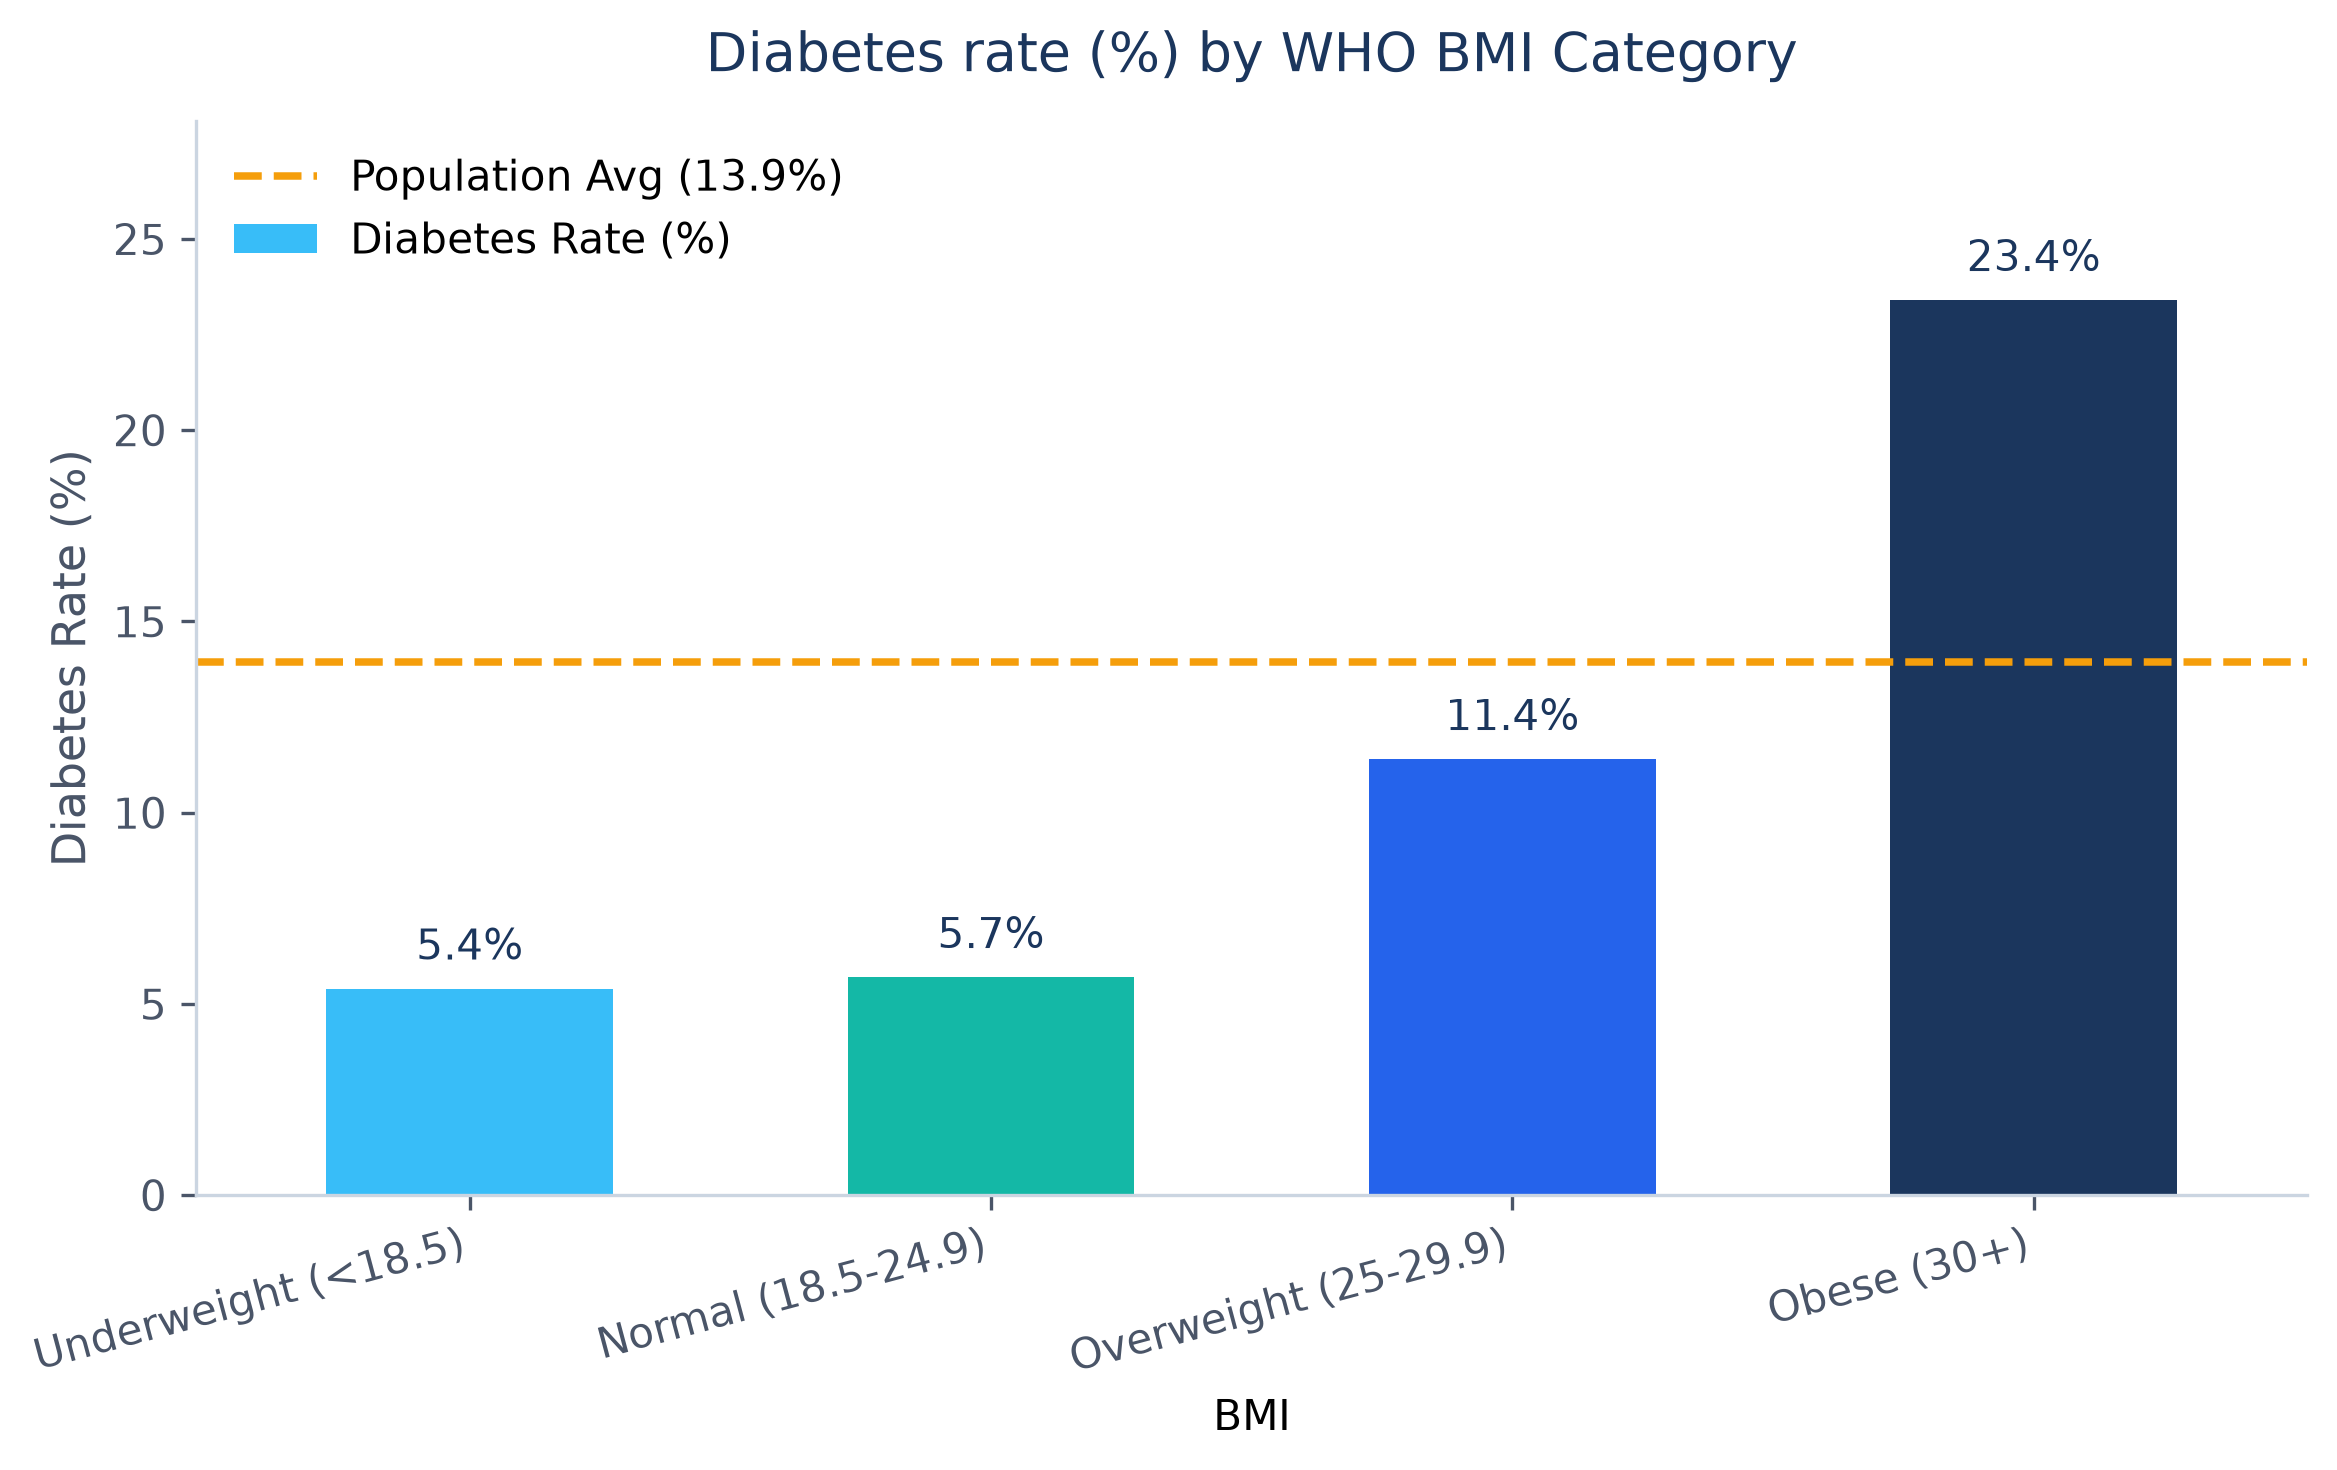

In [144]:
# 4. Chart of Diabetes Prevalence
# What percentage of people with diabetes are in each WHO BMI category?

fig, ax = plt.subplots(figsize=(8, 5), dpi=300)
fig.patch.set_facecolor(CARD_HEX)
ax.set_facecolor(CARD_HEX)

bmi_colors = [SKY_BLUE, TEAL, ROYAL_BLUE, NAVY]
bmi_diabetes_summary['Diabetes Rate (%)'].plot(
    kind='bar',
    color=bmi_colors,
    width=0.55,
    ax=ax
)

ax.set_title('Diabetes rate (%) by WHO BMI Category', fontsize=13, color=NAVY, pad=12)
ax.set_ylabel('Diabetes Rate (%)', fontsize=11, color=SLATE)
# ax.set_xlabel('BMI Category', fontsize=11, color=SLATE)
ax.tick_params(axis='x', rotation=15, colors=SLATE)
ax.tick_params(axis='y', colors=SLATE)
plt.setp(ax.get_xticklabels(), ha='right')

ax.axhline(
    df['Diabetes_binary'].mean() * 100,
    color=AMBER,
    linestyle='--',
    linewidth=1.8,
    label='Population Avg (13.9%)'
)

# Values of percentages to the top of the bars
for bar in ax.patches:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f'{height:.1f}%',
        ha='center',
        va='bottom',
        fontsize=10,
        # fontweight='bold',
        color=NAVY
    )

# Clean borders to match Canva card aesthetic
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.set_ylim(0, bmi_diabetes_summary['Diabetes Rate (%)'].max() * 1.2)
ax.legend(frameon=False, fontsize=10, loc='upper left')
plt.tight_layout()

fig_bmi_cat_path = os.path.join(figures_dir, "eda_bmi_who_categories.png")
plt.savefig(fig_bmi_cat_path, dpi=300, bbox_inches='tight', facecolor=CARD_HEX)
print(f"\nFigure saved: {fig_bmi_cat_path}\n")

plt.show()

Figure saved: figures\eda_clinical_rates.png



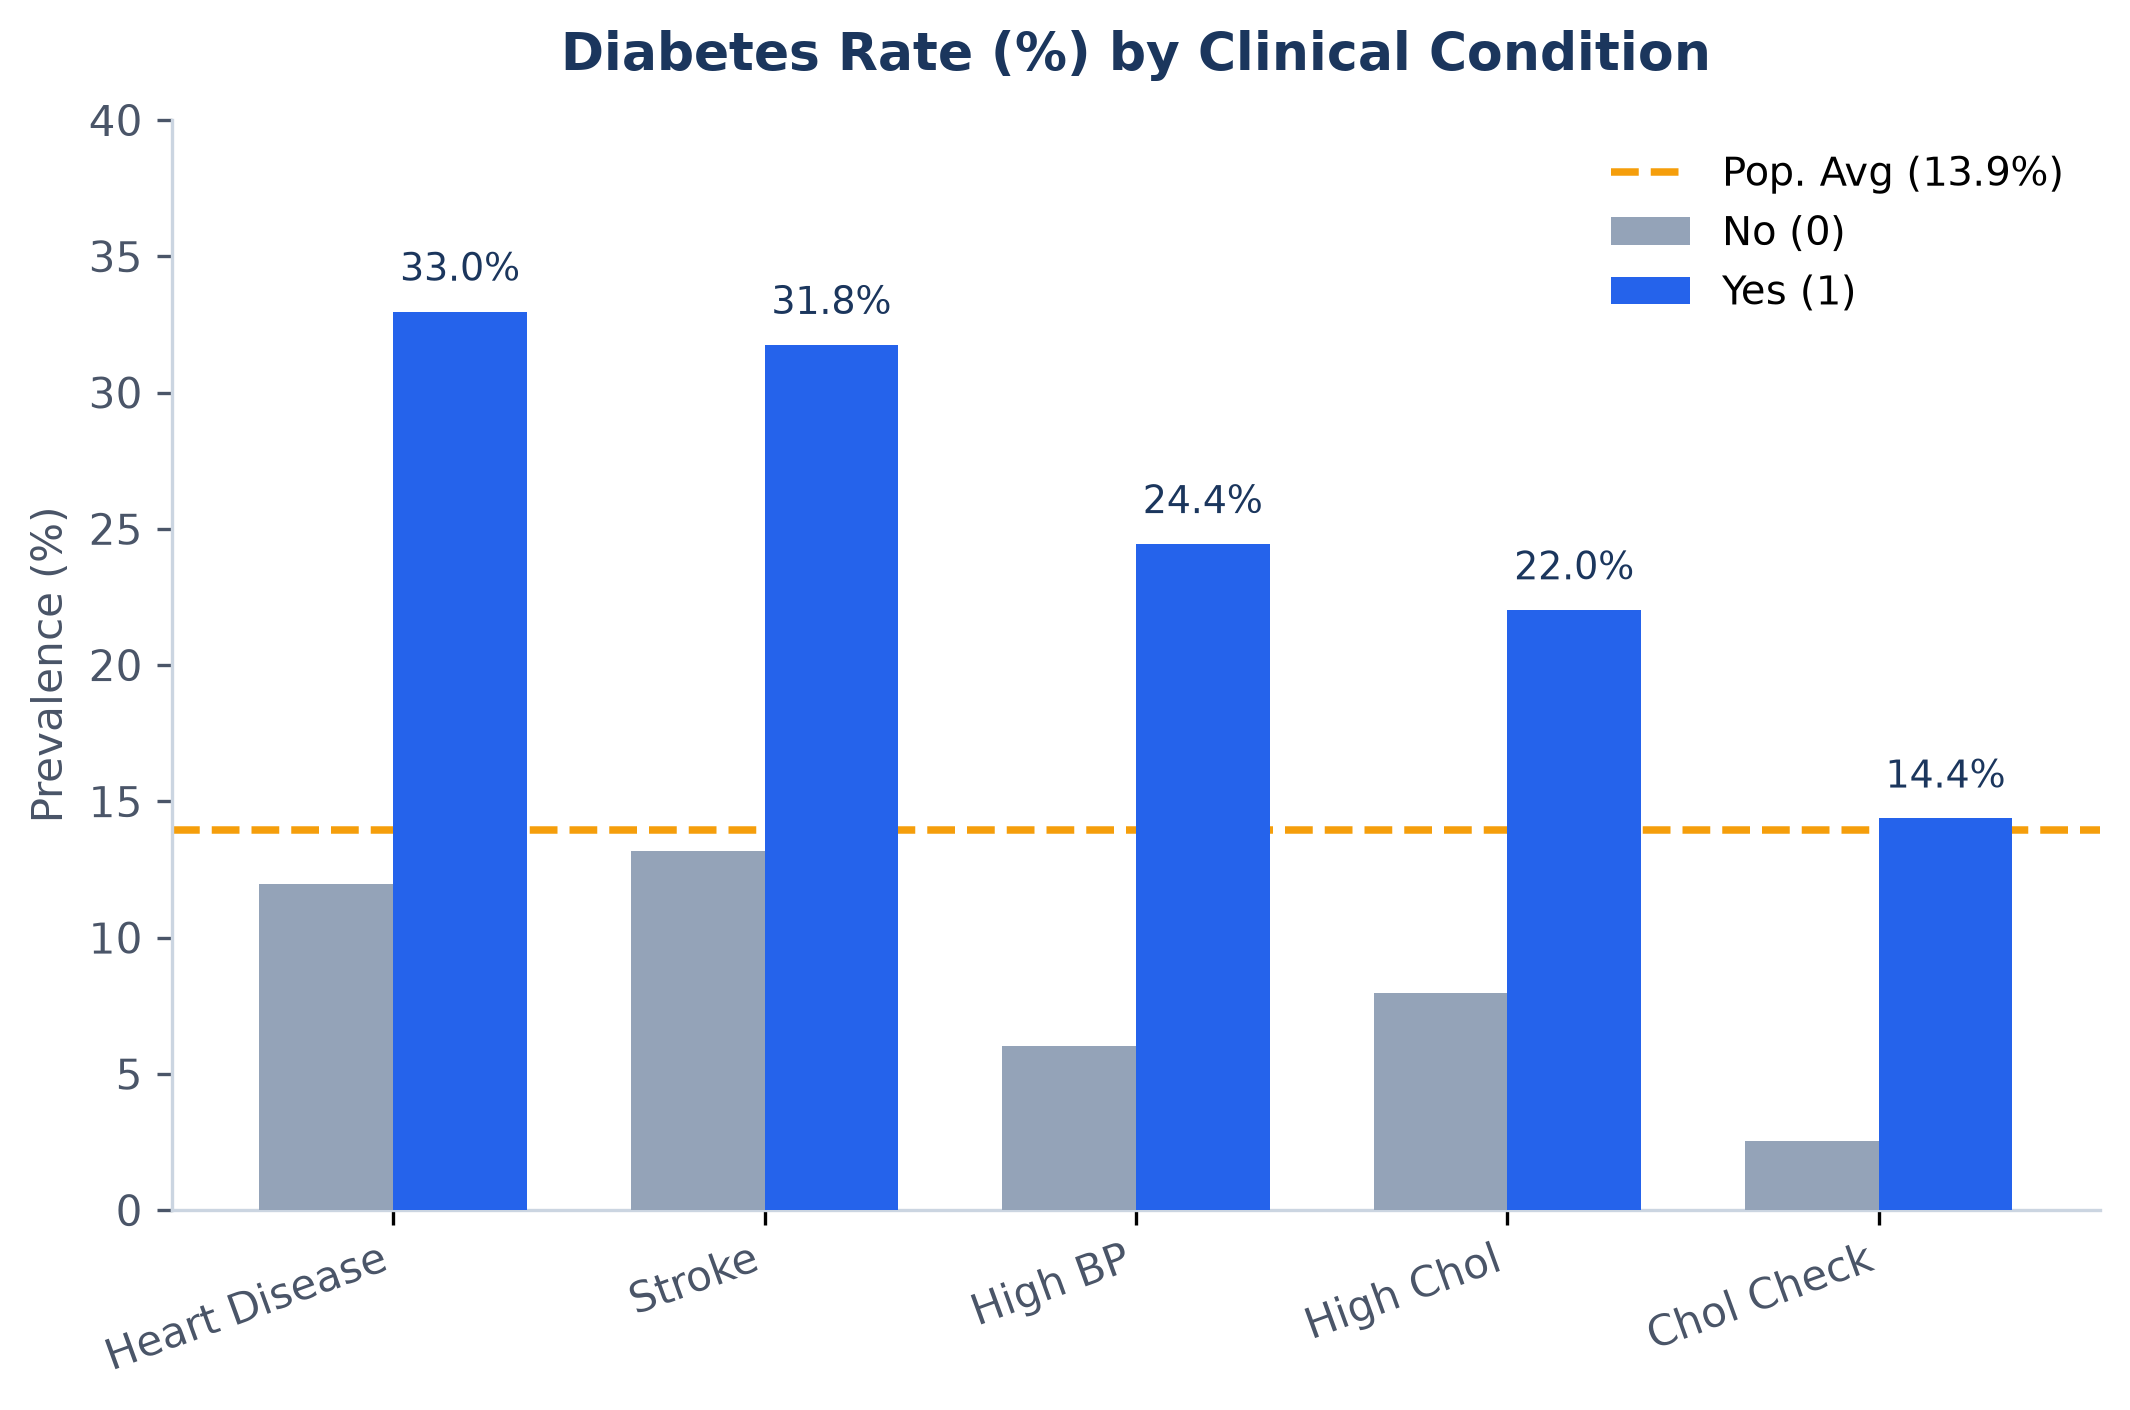

In [150]:
# ============================================================
# 4. Visual summary of binary clinical variables
# ============================================================

# 1. Clean display labels & prevalence of diabetes (%) for 'Yes' vs. 'No'
label_display = {
    'HeartDiseaseorAttack': 'Heart Disease',
    'Stroke': 'Stroke',
    'HighBP': 'High BP',
    'HighChol': 'High Chol',
    'CholCheck': 'Chol Check'
}

risk_rates = []
for col in binary_clinical:
    rates = df.groupby(col)['Diabetes_binary'].mean() * 100
    risk_rates.append({
        'Condition': label_display.get(col, col),
        'No (0)': rates[0],
        'Yes (1)': rates[1]
    })

# Sort descending by 'Yes (1)' prevalence for a clean visual cascade
risk_df = pd.DataFrame(risk_rates).set_index('Condition').sort_values(by='Yes (1)', ascending=False)

# 2. Plot matching the exact Canva slide design
fig, ax = plt.subplots(figsize=(7.2, 4.8), dpi=300)
fig.patch.set_facecolor(CARD_HEX)
ax.set_facecolor(CARD_HEX)

x = np.arange(len(risk_df.index))
w = 0.36

# Population average line first so it appears at the top of the legend
ax.axhline(
    df['Diabetes_binary'].mean() * 100,
    color=AMBER,
    linestyle='--',
    linewidth=1.8,
    label='Pop. Avg (13.9%)',
    zorder=2
)

bars_no = ax.bar(x - w/2, risk_df['No (0)'], w, label='No (0)', color='#94A3B8', zorder=3)
bars_yes = ax.bar(x + w/2, risk_df['Yes (1)'], w, label='Yes (1)', color=ROYAL_BLUE, zorder=3)

# Percentage labels ONLY above the 'Yes (1)' bars (avoids clutter)
for bar in bars_yes:
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h + 0.8,
        f"{h:.1f}%",
        ha='center',
        va='bottom',
        fontsize=9,
        # fontweight='bold',
        color=NAVY
    )

ax.set_title('Diabetes Rate (%) by Clinical Condition', fontsize=12.5, fontweight='bold', color=NAVY, pad=12)
ax.set_ylabel('Prevalence (%)', fontsize=10, color=SLATE)
ax.set_xticks(x)
ax.set_xticklabels(risk_df.index, rotation=20, ha='right', fontsize=10, color=SLATE)
ax.tick_params(axis='y', labelsize=10, colors=SLATE)
ax.set_ylim(0, 40)

# Clean borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False, fontsize=9.5, loc='upper right')
plt.tight_layout()

fig1_path = os.path.join(figures_dir, "eda_clinical_rates.png")
plt.savefig(fig1_path, dpi=300, bbox_inches='tight', facecolor=CARD_HEX)
print(f"Figure saved: {fig1_path}\n")

plt.show()

**The EDA supports hypothesis H2 (“clinical conditions are the strongest predictors”).**

*Diabetes rate:* 
- The red line indicates the population average (13.9%). 
- The presence of any of clinical conditions (“Yes” (1)) drastically raises the risk of diabetes above this level 
- (HighBP: ~24.5%, HighChol: ~22.0%, Stroke: ~31.8%, HeartDiseaseorAttack: ~33.0%).

*Shift in BMI (boxplot):*
- The median BMI for the healthy group (0.0) is 27.0 (mean: 27.8, IQR: 24–31).
- The median BMI for the diabetic/prediabetic group (1.0) is 31.0 (mean: 31.9, IQR: 27–35)—which falls into the category of clinical obesity ($\ge 30$).
The entire distribution (the 25th–75th percentile range represented by the box) shifts up by one full category.



Correlation heatmap saved: figures\eda_clinical_correlation.png



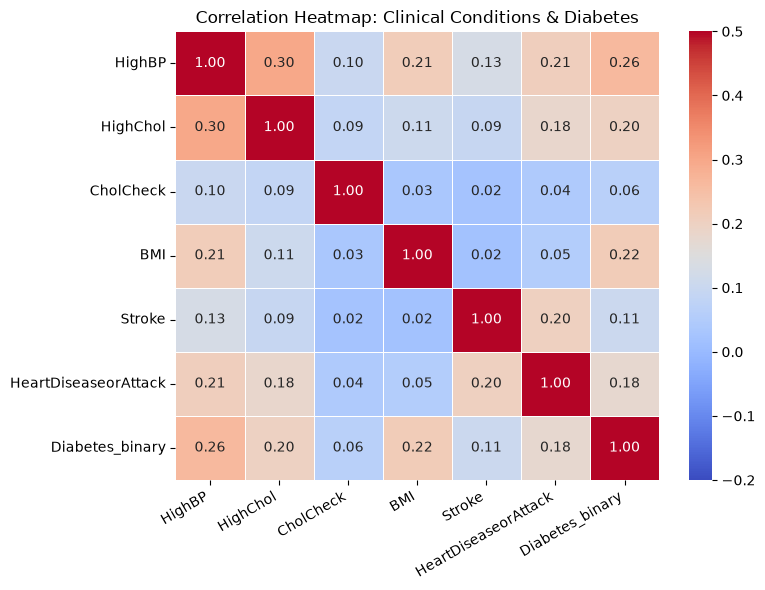

In [88]:
# 2. Correlation heatmap: clinical conditions and diabetes
cols_to_corr = clinical_cols + ['Diabetes_binary']

# Calculation of the correlation matrix
corr_matrix = df[cols_to_corr].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,           
    fmt=".2f",            
    cmap="coolwarm",      
    vmin=-0.2,            
    vmax=0.5,             
    linewidths=0.5
)
plt.title('Correlation Heatmap: Clinical Conditions & Diabetes')
plt.xticks(rotation=30, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

fig_corr_path = os.path.join(figures_dir, "eda_clinical_correlation.png")
plt.savefig(fig_corr_path, dpi=300, bbox_inches='tight')
print(f"Correlation heatmap saved: {fig_corr_path}\n")

plt.show()

The strongest linear associations with the `Diabetes_binary` variable (bottom row) are as follows:
- `HighBP` (0.26) – this shows the strongest positive correlation with diabetes.
- `BMI` (0.22) – the second strongest association.
- `HighChol` (0.20) – the third strongest.
- `HeartDiseaseorAttack` (0.18) – a moderately strong association; however, among those affected, the prevalence of diabetes is 33%.

--- Classification Report (Baseline Random Forest) ---
              precision    recall  f1-score   support

         0.0       0.95      0.73      0.83     43667
         1.0       0.31      0.76      0.45      7069

    accuracy                           0.74     50736
   macro avg       0.63      0.75      0.64     50736
weighted avg       0.86      0.74      0.77     50736

ROC-AUC Score: 0.8232

Figure saved: figures\rf_feature_importance.png



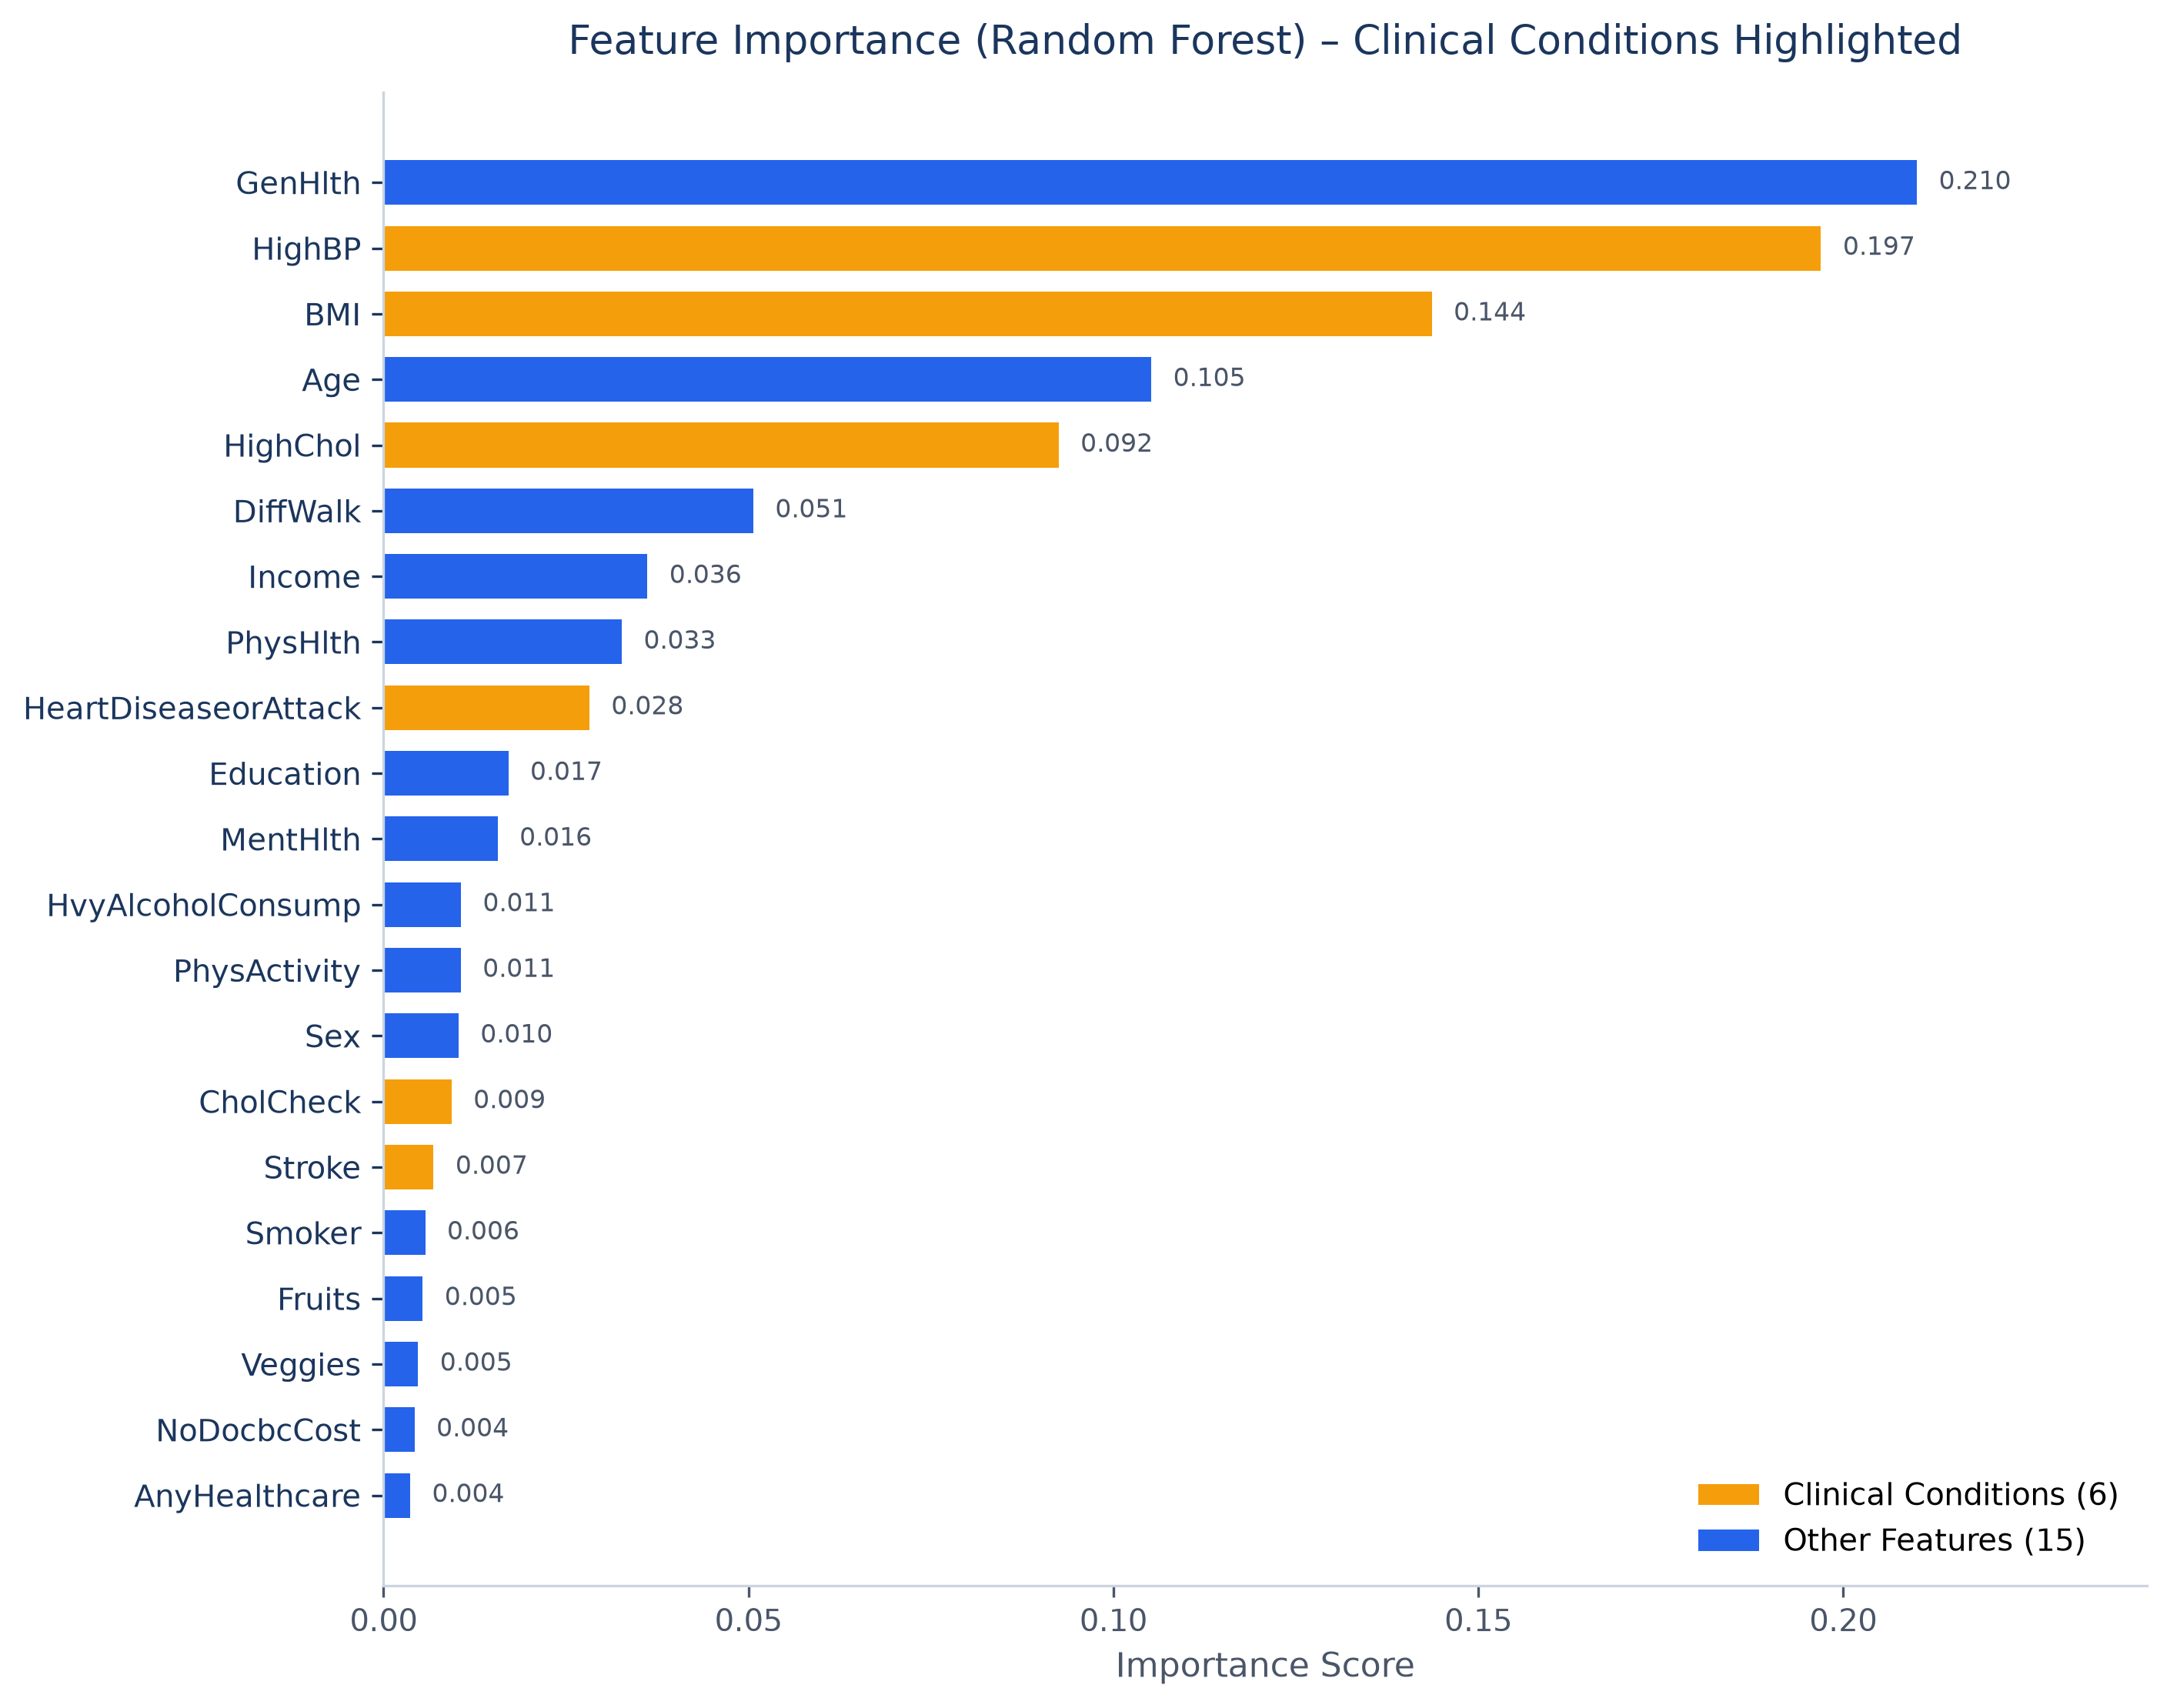

In [148]:
# 3. Classification report with Random Forest model / Feature importance chart

X = df.drop(columns=['Diabetes_binary'])
y = df['Diabetes_binary']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

rf_baseline = RandomForestClassifier(
    n_estimators=100,
    max_depth=12,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_baseline.fit(X_train, y_train)

y_pred = rf_baseline.predict(X_test)
y_proba = rf_baseline.predict_proba(X_test)[:, 1]

print("--- Classification Report (Baseline Random Forest) ---")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

# Sort importances ascending for horizontal bar chart
importances = pd.Series(rf_baseline.feature_importances_, index=X.columns).sort_values(ascending=True)

# Plot matching Canva palette
fig, ax = plt.subplots(figsize=(9.5, 7.5), dpi=300)
fig.patch.set_facecolor(CARD_HEX)
ax.set_facecolor(CARD_HEX)

colors = [AMBER if col in clinical_cols else ROYAL_BLUE for col in importances.index]
bars = ax.barh(importances.index, importances.values, color=colors, height=0.68)

ax.set_title(
    'Feature Importance (Random Forest) – Clinical Conditions Highlighted',
    fontsize=12.5,
    # fontweight='bold',
    color=NAVY,
    pad=12
)
ax.set_xlabel('Importance Score', fontsize=10.5, color=SLATE)
ax.tick_params(axis='x', labelsize=9.5, colors=SLATE)
ax.tick_params(axis='y', labelsize=9.5, colors=NAVY)
ax.set_xlim(0, importances.max() * 1.15)

# Add subtle value labels at the end of the bars
for bar in bars:
    w = bar.get_width()
    ax.text(
        w + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f"{w:.3f}",
        va='center',
        ha='left',
        fontsize=8,
        color=SLATE
    )

# Clean borders and legend matching Canva aesthetic
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor=AMBER, label='Clinical Conditions (6)'),
    Patch(facecolor=ROYAL_BLUE, label='Other Features (15)')
]
ax.legend(handles=legend_elements, frameon=False, fontsize=9.5, loc='lower right')

plt.tight_layout()

fig3_path = os.path.join(figures_dir, "rf_feature_importance.png")
plt.savefig(fig3_path, dpi=300, bbox_inches='tight', facecolor=CARD_HEX)
print(f"\nFigure saved: {fig3_path}\n")

plt.show()

Figure saved: figures\rf_clinical_feature_importance.png



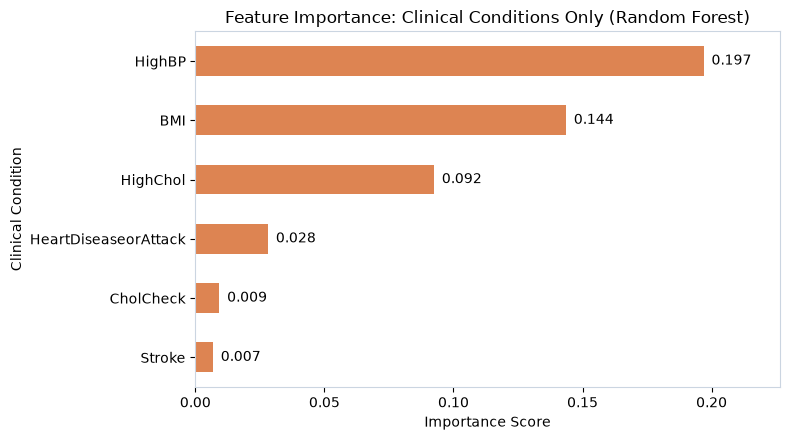

In [151]:
# 4. Classification report / Feature importance chart only with CLinical Conditions


# Filter and ranking of the importance of only the clinical_cols
clinical_importances = (
    pd.Series(rf_baseline.feature_importances_, index=X.columns)[clinical_cols]
    .sort_values(ascending=True)
)

plt.figure(figsize=(8, 4.5))
ax = clinical_importances.plot(kind='barh', color='#DD8452')

plt.title('Feature Importance: Clinical Conditions Only (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Clinical Condition')

# Displaying values at the ends of the columns
for bar in ax.patches:
    width = bar.get_width()
    ax.text(
        width + 0.003,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.3f}',
        va='center',
        fontsize=10
    )

plt.xlim(0, clinical_importances.max() * 1.15)
plt.tight_layout()

fig4_path = os.path.join(figures_dir, "rf_clinical_feature_importance.png")
plt.savefig(fig4_path, dpi=300, bbox_inches='tight')
print(f"Figure saved: {fig4_path}\n")

plt.show()

=== BASELINE RANDOM FOREST METRICS ===
ROC-AUC:   0.8232
Recall:    0.7635
Precision: 0.3146
F1-Score:  0.4456

Figure saved: figures\rf_baseline_confusion_matrix.png


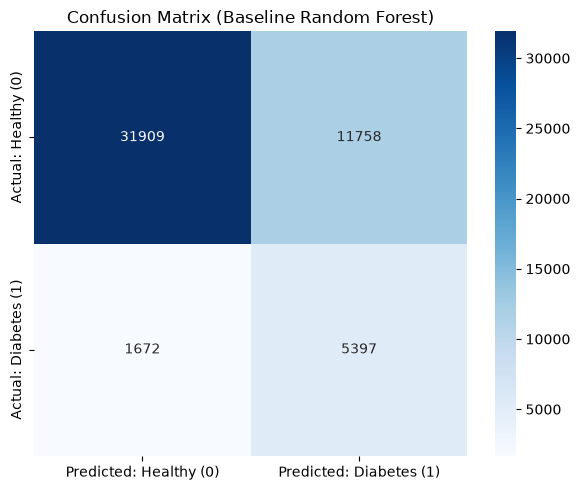

In [152]:
# ============================================================
# 5. Baseline (rf_baseline) and RiskScore (predict_proba)
# ============================================================


# 1.Base model forecasts and metrics
y_pred_base = rf_baseline.predict(X_test)
y_proba_base = rf_baseline.predict_proba(X_test)[:, 1]

print("=== BASELINE RANDOM FOREST METRICS ===")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_base):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_base):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_base):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_base):.4f}")

# 2. Confusion Matrix
plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred_base)
sns.heatmap(
    cm, annot=True, fmt='d', cmap='Blues',
    xticklabels=['Predicted: Healthy (0)', 'Predicted: Diabetes (1)'],
    yticklabels=['Actual: Healthy (0)', 'Actual: Diabetes (1)']
)
plt.title('Confusion Matrix (Baseline Random Forest)')
plt.tight_layout()

cm_path = os.path.join(figures_dir, "rf_baseline_confusion_matrix.png")
plt.savefig(cm_path, dpi=300, bbox_inches='tight')
print(f"\nFigure saved: {cm_path}")

plt.show()


**ROC-AUC**: 0.8232 – indicates high discriminative power.

**Recall**: 0.7635 (76.4%) – With `class_weight='balanced'`, the baseline model identifies more than three-quarters of actual diabetics.

**Risk Score (`predict_proba`)**: 
- Real healthy individuals (0.0) receive an average risk score of 0.333 (median: 0.286)
- diabetics (1.0) receive an average score of 0.634 (median: 0.679)
- this provides an excellent foundation for defining green, yellow, and red risk zones!

Figure saved: figures\rf_baseline_roc_curve.png



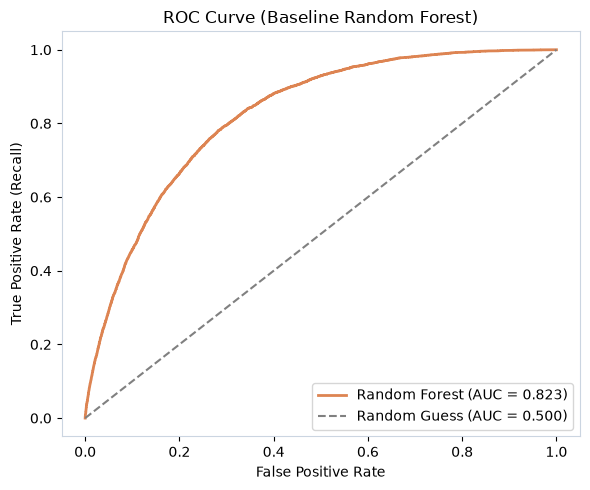


--- Risk Score (predict_proba) statistics on the test set ---
          count   mean    std    min    25%    50%    75%    max
Actual                                                          
0.0     43667.0  0.333  0.242  0.007  0.114  0.286  0.520  0.935
1.0      7069.0  0.634  0.196  0.026  0.511  0.679  0.786  0.950


In [153]:
# 3. ROC Curve fig
fpr, tpr, thresholds = roc_curve(y_test, y_proba_base)
auc_score = roc_auc_score(y_test, y_proba_base)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='#DD8452', lw=2, label=f'Random Forest (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Guess (AUC = 0.500)')
plt.title('ROC Curve (Baseline Random Forest)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.tight_layout()

roc_path = os.path.join(figures_dir, "rf_baseline_roc_curve.png")
plt.savefig(roc_path, dpi=300, bbox_inches='tight')
print(f"Figure saved: {roc_path}\n")

plt.show()

# 4. Checking the distribution of the Risk Score (predict_proba)
risk_eval_df = pd.DataFrame({'Actual': y_test, 'Risk_Score': y_proba_base})
print("\n--- Risk Score (predict_proba) statistics on the test set ---")
print(risk_eval_df.groupby('Actual')['Risk_Score'].describe().round(3))

In [107]:
# 5. fine tuning - RandomizedSearchCV + cross validation

start_time = time.time()

# 5a. Fine-tuning to prevent overfitting
param_dist = {
    'n_estimators': [100, 200],
    'max_depth': [10, 12, 15, 18],
    'min_samples_leaf': [5, 10, 20, 30],
    'min_samples_split': [10, 20, 40],
    'max_features': ['sqrt', 'log2', 0.3]
}

rf_base_estimator = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# 5b. RandomizedSearchCV - with ROC-AUC optimization
random_search = RandomizedSearchCV(
    estimator=rf_base_estimator,
    param_distributions=param_dist,
    n_iter=10,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

elapsed = time.time() - start_time
print(f"\nFine-tuning is done: ({elapsed:.1f} sec).")
print("Best parameters:", random_search.best_params_)
print(f"Best CV ROC-AUC: {random_search.best_score_:.4f}")

# 5c. Evaluation of best modells
rf_tuned = random_search.best_estimator_
y_pred_tuned = rf_tuned.predict(X_test)
y_proba_tuned = rf_tuned.predict_proba(X_test)[:, 1]

print("\n=== TUNED RANDOM FOREST METRICS (TEST SET) ===")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_proba_tuned):.4f}  (Baseline: {roc_auc_score(y_test, y_proba_base):.4f})")
print(f"Recall:    {recall_score(y_test, y_pred_tuned):.4f}  (Baseline: {recall_score(y_test, y_pred_base):.4f})")
print(f"Precision: {precision_score(y_test, y_pred_tuned):.4f}  (Baseline: {precision_score(y_test, y_pred_base):.4f})")
print(f"F1-Score:  {f1_score(y_test, y_pred_tuned):.4f}  (Baseline: {f1_score(y_test, y_pred_base):.4f})")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters: {'n_estimators': 200, 'min_samples_split': 40, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 12}
Best CV ROC-AUC: 0.8283

=== TUNED RANDOM FOREST METRICS (TEST SET) ===
ROC-AUC:   0.8239  (Baseline: 0.8232)
Recall:    0.7741  (Baseline: 0.7635)
Precision: 0.3095  (Baseline: 0.3146)
F1-Score:  0.4422  (Baseline: 0.4456)




**ROC-AUC** improved (0.8232 → 0.8239): 
- the model's overall show a consistent increase
- the 3-fold cross-validation result (0.8283) confirms that the model is not overfitted
- recall has further increased (76.35% → 77.41%): A greater number of actual diabetic cases were successfully identified.

=== H2 EXPERIMENT: ALL 21 FEATURES vs. 6 CLINICAL FEATURES ONLY ===
                       Full Model (21 Features)  Clinical Only (6 Features)
ROC-AUC                                  0.8239                      0.7801
Recall\n(Sensitivity)                    0.7741                      0.7408
F1-Score                                 0.4422                      0.4004
Precision                                0.3095                      0.2744

Comparison figure saved to: figures\rf_h2_full_vs_clinical.png


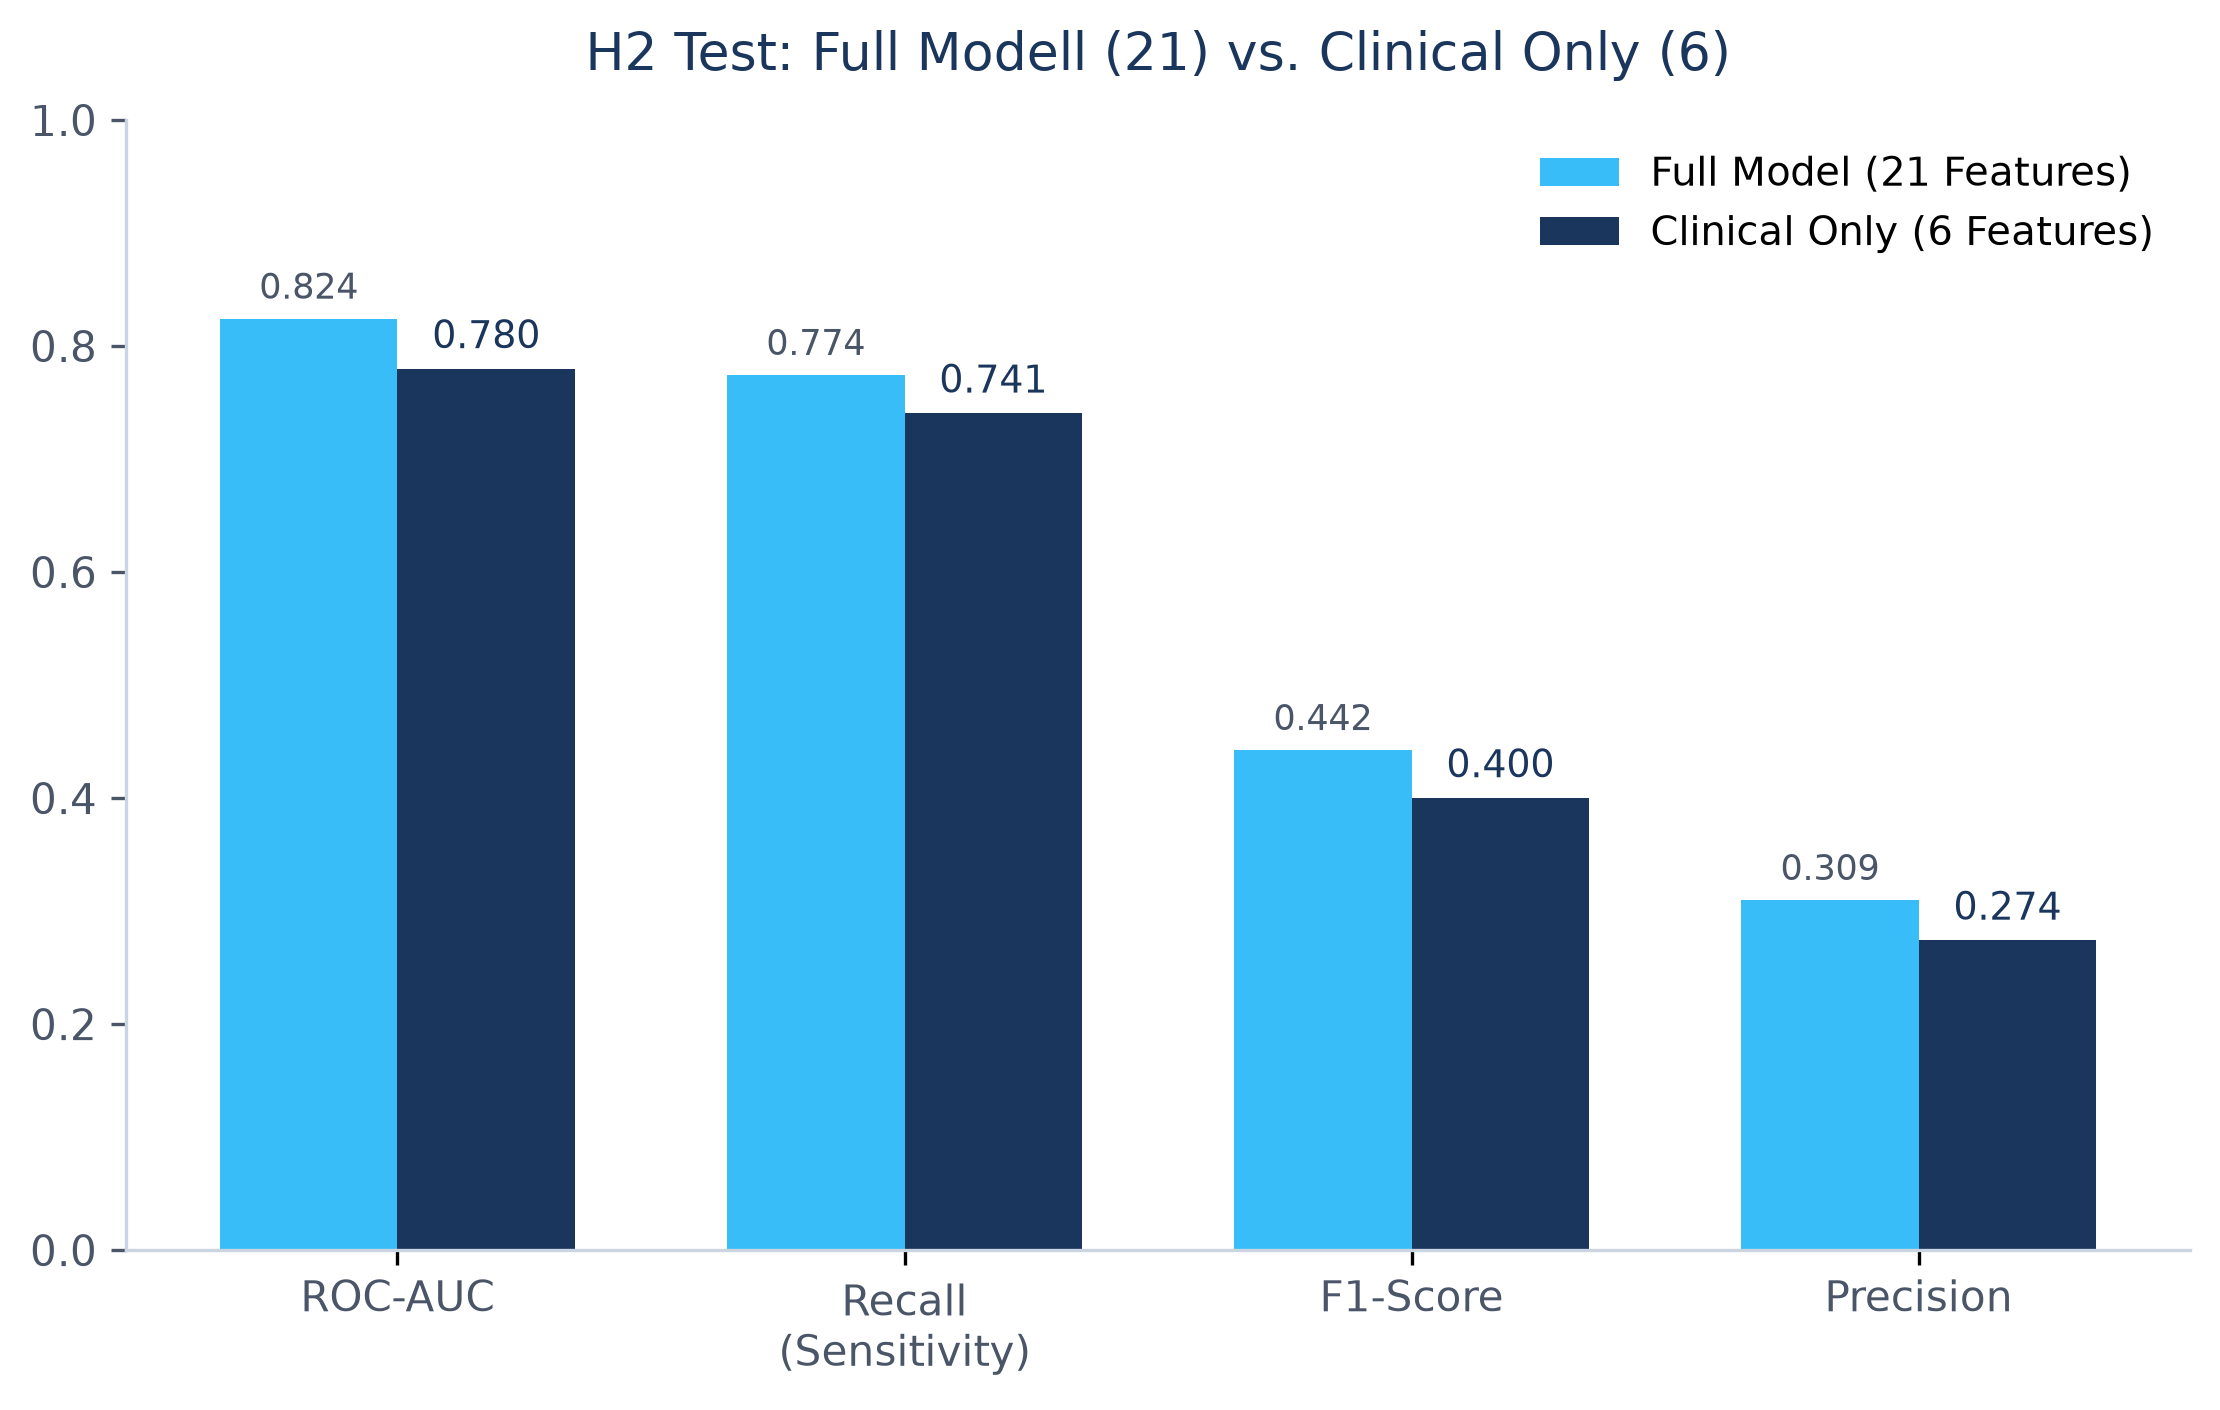

In [146]:
# 6. Random Forest H2 Experiment (All 21 Features vs. 6 Clinical Features)

# 6a. Subset train and test sets to the 6 clinical features only
X_train_clinical = X_train[clinical_cols]
X_test_clinical = X_test[clinical_cols]

# 6b. Train the tuned Random Forest model using only the 6 clinical features
rf_clinical_only = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=40,
    min_samples_leaf=5,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_clinical_only.fit(X_train_clinical, y_train)

y_pred_clinical = rf_clinical_only.predict(X_test_clinical)
y_proba_clinical = rf_clinical_only.predict_proba(X_test_clinical)[:, 1]

# 6c. Create performance comparison table (exact metric order & labels)
comparison_df = pd.DataFrame({
    'Full Model (21 Features)': [
        roc_auc_score(y_test, y_proba_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned)
    ],
    'Clinical Only (6 Features)': [
        roc_auc_score(y_test, y_proba_clinical),
        recall_score(y_test, y_pred_clinical),
        f1_score(y_test, y_pred_clinical),
        precision_score(y_test, y_pred_clinical)
    ]
}, index=['ROC-AUC', 'Recall\n(Sensitivity)', 'F1-Score', 'Precision']).round(4)

print("=== H2 EXPERIMENT: ALL 21 FEATURES vs. 6 CLINICAL FEATURES ONLY ===")
print(comparison_df)

# 6d. Plot comparison chart matching reference slide style
fig, ax = plt.subplots(figsize=(7.5, 4.8), dpi=300)
fig.patch.set_facecolor(CARD_HEX)
ax.set_facecolor(CARD_HEX)

x = np.arange(len(comparison_df.index))
w = 0.35

bars_full = ax.bar(
    x - w/2,
    comparison_df['Full Model (21 Features)'],
    w,
    label='Full Model (21 Features)',
    color=SKY_BLUE
)
bars_clin = ax.bar(
    x + w/2,
    comparison_df['Clinical Only (6 Features)'],
    w,
    label='Clinical Only (6 Features)',
    color=NAVY
)

ax.set_title('H2 Test: Full Modell (21) vs. Clinical Only (6)', fontsize=12.5, color=NAVY, pad=12)
ax.set_xticks(x)
ax.set_xticklabels(comparison_df.index, fontsize=10, color=SLATE)
ax.tick_params(axis='y', labelsize=10, colors=SLATE)
ax.set_ylim(0, 1.0)

# Value labels matching exact style
for bar in bars_full:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.018, f"{h:.3f}", ha='center', fontsize=8.5, color=SLATE)

for bar in bars_clin:
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, h + 0.018, f"{h:.3f}", ha='center', fontsize=9, color=NAVY)

# Clean borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.legend(frameon=False, fontsize=9.5, loc='upper right')
plt.tight_layout()

comparison_fig_path = os.path.join(figures_dir, "rf_h2_full_vs_clinical.png")
plt.savefig(comparison_fig_path, dpi=300, bbox_inches='tight', facecolor=CARD_HEX)
print(f"\nComparison figure saved to: {comparison_fig_path}")

plt.show()

Even after removing the other questions the modell remains highly effective:
- The full 21-variable model achieves a ROC-AUC of 0.8239 and a Recall of 77.41%.
- If we use only the 6 clinical indicators (HighBP, HighChol, CholCheck, BMI, Stroke, HeartDiseaseorAttack), the model still yields a ROC-AUC of 0.7801 and a Recall of 74.08%
- This means that these 6 simple clinical indicators alone provide ~95% of the full model’s predictive power (in terms of ROC-AUC) and enable the identification of over 74% of the patients.

Why is this valuable for our Risk Assessment app?
- Quick Risk Check: In a mobile app or a rapid screening setting (such as at a pharmacy or a GP’s office), users are unlikely to have the patience to answer 21 questions. This result demonstrates that a 6-question "Clinical Fast-Track" mode can provide a reliable initial screening.
- The role of the remaining 15 variables (fine-tuning): The other 15 variables (covering lifestyle, demographics, and general health status) serve to fine-tuning accuracy—improving Precision (from 0.2744 to 0.3095) and the AUC (from 0.7801 to 0.8239)—when the full questionnaire is completed.

### 1. Detailed Summary

**Data Quality & Clinical EDA**

* **Clean Dataset:** Across all 253,680 respondents, there are zero missing values (`0` NaNs). The target variable (`Diabetes_binary`) is significantly imbalanced: **13.93%** (35,346 individuals) have diabetes or prediabetes, while **86.07%** are healthy.
* **Clinical Risk Factors:** Respondents with high blood pressure (`HighBP`) show a **4x higher** diabetes prevalence (**24.45%** vs. 6.04%), while those with high cholesterol (`HighChol`) show nearly **3x higher** prevalence (**22.01%** vs. 7.98%). Over one-third of individuals with heart disease or stroke have diabetes (**32.97%** and **31.75%**, respectively), though these conditions are much rarer in the general population (9.42% and 4.06%).
* **BMI & WHO Categories:** Diabetic respondents have a mean BMI more than 4 points higher than healthy individuals (**31.94** vs. 27.81; median: 31 vs. 27). Breaking BMI down into WHO categories reveals a sharp jump: diabetes prevalence rises from **5.7%** in the Normal weight group and **11.4%** in the Overweight group to **23.4%** in the Obese (`30+`) category.



**Random Forest Modeling & Hyperparameter Tuning**

* **Handling Class Imbalance (`class_weight='balanced'`):** Because identifying positive cases (Recall) is critical for a medical screening app, we trained the model using balanced class weights. The baseline Random Forest achieved a **0.8232 ROC-AUC** and **76.35% Recall**.


* **Hyperparameter Tuning (`RandomizedSearchCV`):** Using 3-fold cross-validation, we identified the optimal parameters (`n_estimators=200`, `max_depth=12`, `min_samples_split=40`, `min_samples_leaf=5`). On the test set, this improved **ROC-AUC to 0.8239** and **Recall to 77.41%** (with a CV ROC-AUC of 0.8283, confirming strong generalization with no overfitting).
* **Risk Scoring (`predict_proba`):** The predicted probability scores cleanly separate the two groups: healthy individuals have a median risk score of **0.286**, whereas diabetic individuals have a median score of **0.679**—providing a solid foundation for the app's three-tier (Low / Moderate / High) alert zones.

**Validating Hypothesis H2 (6 Clinical Features vs. All 21 Features)**

* In the global Feature Importance ranking, `HighBP` (#2) and `BMI` (#3) ranked right behind general health (`GenHlth`), with `HighChol` (#5) also in the Top 5.


* **The Decisive Experiment:** When we dropped 15 questions out of 21 and trained the tuned Random Forest exclusively on the **6 clinical conditions**, the model still achieved a **0.7801 ROC-AUC** and **74.08% Recall**—retaining roughly **95%** of the full model's predictive power.



---

### 2. In a Nutshell – Key Takeaways

* **Hypothesis H2 Confirmed:** Clinical indicators are among the strongest predictors of diabetes, with `HighBP` and `BMI` ranking in the Top 3 and `HighChol` in the Top 5 features overall.


* **Fewer Questions, Nearly Identical Power:** Using only our 6 clinical features instead of all 21 survey questions still achieves a **0.780 ROC-AUC** (vs. **0.824** for the full model) and captures **74.1%** of diabetic cases.


* **Real-World App Value:** This enables a **6-question "Quick Risk Check"** mode for fast screening, while the full 21-question model delivers **77.4% Recall** to reliably sort users into green, yellow, and red risk zones.
* **Production-Ready Code:** The training, evaluation, and risk-scoring functions are modularized in `rf_model.py`, and the trained model is saved as a compressed `.joblib` artifact ready for immediate inference without retraining.

In [ ]:
# ============================================================
# 5. Python module script calling code
# ============================================================

import sys
import os

# Add the project root directory (one level up) to Python's module search path
sys.path.append(os.path.abspath(".."))

# Import functions from model/rf_model.py (adjust 'model' if your folder is named 'models')
from model.rf_model import (
    train_random_forest,
    evaluate_random_forest,
    get_risk_scores,
    save_model
)

# 1. Train tuned Random Forest
rf_final = train_random_forest(X_train, y_train)

# 2. Evaluate on test set
metrics, y_pred, y_proba = evaluate_random_forest(rf_final, X_test, y_test)

# 3. Save model to ../models/random_forest.joblib (one level up from notebooks/)
save_model(rf_final, filepath="../models/random_forest.joblib", compress=3)

# 4. Preview Risk Scoring output
risk_preview = get_risk_scores(rf_final, X_test.head(5))
print("\nSample Risk Scoring Output:")
print(risk_preview)